# Control óptimo de EDOs — Clase 4
**Resolución numérica: FBSM, tiro y métodos directos**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

## 0. Existencia: chattering y un problema sin candidato
**Chattering:** $\min\int_0^1x^2+(u^2-1)^2$, $\dot x=u$, $x(0)=0$, $u\in\mathbb R$. Con $u_k=\pm1$ alternando cada $1/(2k)$,
$J(u_k)=\frac1{12k^2}\to0$, pero ningún control da $J=0$: **no hay óptimo** (el costo no es convexo en $u$).

k=  1  J(u_k)=8.333e-02   1/(12k^2)=8.333e-02
k=  2  J(u_k)=2.083e-02   1/(12k^2)=2.083e-02
k=  4  J(u_k)=5.208e-03   1/(12k^2)=5.208e-03
k=  8  J(u_k)=1.302e-03   1/(12k^2)=1.302e-03
k= 16  J(u_k)=3.254e-04   1/(12k^2)=3.255e-04
k= 32  J(u_k)=8.134e-05   1/(12k^2)=8.138e-05
u = 0 (el promedio de los pozos):  J = 1.0


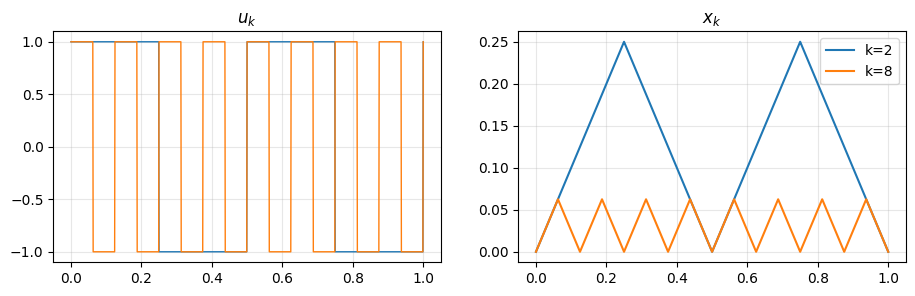

In [2]:
t0 = np.linspace(0, 1, 200001)
def integral(v, t):
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))
for k in [1, 2, 4, 8, 16, 32]:
    uk = np.where(np.floor(2*k*t0) % 2 == 0, 1.0, -1.0)
    xk = np.concatenate([[0], np.cumsum(0.5*(uk[1:] + uk[:-1])*np.diff(t0))])
    print(f'k={k:3d}  J(u_k)={integral(xk**2 + (uk**2 - 1)**2, t0):.3e}   1/(12k^2)={1/(12*k**2):.3e}')
print('u = 0 (el promedio de los pozos):  J =', integral(np.ones_like(t0), t0))
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for k in [2, 8]:
    uk = np.where(np.floor(2*k*t0) % 2 == 0, 1.0, -1.0)
    xk = np.concatenate([[0], np.cumsum(0.5*(uk[1:] + uk[:-1])*np.diff(t0))])
    ax[0].plot(t0[::200], uk[::200], lw=1, label=f'k={k}'); ax[1].plot(t0, xk, label=f'k={k}')
ax[0].set_title('$u_k$'); ax[1].set_title('$x_k$'); ax[1].legend(); plt.show()

**Sin cota y sin candidato:** $\max\int_0^1x$, $\dot x=u$, $x(0)=0$, $u\in\mathbb R$. Con $u\equiv k$, $J=k/2\to\infty$.
El PMP da $\lambda=1-t$ y $H_u=\lambda\neq0$: no hay ningún candidato (consistente: no hay óptimo; falla la coercividad).

In [3]:
for k in [1, 10, 100]:
    print(f'u = {k:4d}:  J = {integral(k*t0, t0):.1f}')

u =    1:  J = 0.5
u =   10:  J = 5.0
u =  100:  J = 50.0


## 1. El Forward–Backward Sweep
Leer la función con atención: los cuatro pasos de la clase están marcados.

In [4]:
def rk4(F, y0, t):
    """Integra y' = F(t, y) en la grilla t con Runge-Kutta 4."""
    y = np.zeros((len(t), np.size(y0))); y[0] = y0
    for k in range(len(t) - 1):
        h = t[k+1] - t[k]
        k1 = F(t[k], y[k]); k2 = F(t[k] + h/2, y[k] + h/2*k1)
        k3 = F(t[k] + h/2, y[k] + h/2*k2); k4 = F(t[k] + h, y[k] + h*k3)
        y[k+1] = y[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y

def fbsm(f, dlam, ucalc, x0, lamT, T, N=1000, m=1, u0=None,
         omega=0.5, tol=1e-3, maxit=2000, historia=False):
    """Forward-Backward Sweep (Lenhart & Workman, cap. 4). Problema de MÁXIMO.
    f(t,x,u)        -> x'                  (arreglos de dimensión n)
    dlam(t,x,u,lam) -> lam' = -H_x
    ucalc(t,x,lam)  -> control dado por el PMP (dimensión m)
    lamT(xT)        -> lam(T) (condición de transversalidad)
    Devuelve un diccionario con t, x, u, lam, iteraciones (y la historia de u)."""
    t = np.linspace(0, T, N+1); h = T/N
    x0 = np.atleast_1d(np.asarray(x0, float)); n = len(x0)
    u = np.zeros((N+1, m)) if u0 is None else np.array(u0, float).reshape(N+1, m)
    x = np.zeros((N+1, n)); lam = np.zeros((N+1, n)); hist = []
    rel = lambda a, b: np.sum(np.abs(a - b)) / max(np.sum(np.abs(a)), 1e-12)
    for it in range(maxit):
        uo, xo, lo = u.copy(), x.copy(), lam.copy()
        x[0] = x0                                   # Paso 1: estado hacia adelante
        for k in range(N):
            um = 0.5*(u[k] + u[k+1])
            k1 = f(t[k], x[k], u[k]); k2 = f(t[k]+h/2, x[k]+h/2*k1, um)
            k3 = f(t[k]+h/2, x[k]+h/2*k2, um); k4 = f(t[k]+h, x[k]+h*k3, u[k+1])
            x[k+1] = x[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
        lam[N] = lamT(x[N])                         # Paso 2: adjunto hacia atrás
        for k in range(N, 0, -1):
            um = 0.5*(u[k] + u[k-1]); xm = 0.5*(x[k] + x[k-1])
            k1 = dlam(t[k], x[k], u[k], lam[k])
            k2 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k1)
            k3 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k2)
            k4 = dlam(t[k]-h, x[k-1], u[k-1], lam[k] - h*k3)
            lam[k-1] = lam[k] - h/6*(k1 + 2*k2 + 2*k3 + k4)
        u1 = np.array([np.atleast_1d(ucalc(t[k], x[k], lam[k])) for k in range(N+1)]).reshape(N+1, m)
        u = omega*u1 + (1 - omega)*uo               # Paso 3: actualizar con relajación
        if historia: hist.append(u.copy())
        if it > 0 and max(rel(u, uo), rel(x, xo), rel(lam, lo)) < tol:   # Paso 4
            break
    return dict(t=t, x=x, u=u, lam=lam, iters=it+1, hist=hist)

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

## 2. Lab 1 de Lenhart–Workman
$\max\int_0^1(Ax-Bu^2)$, $\dot x=-\frac12x^2+Cu$. \quad $u=\frac{C\lambda}{2B}$, $\dot\lambda=-A+\lambda x$, $\lambda(1)=0$.

iteraciones: 17


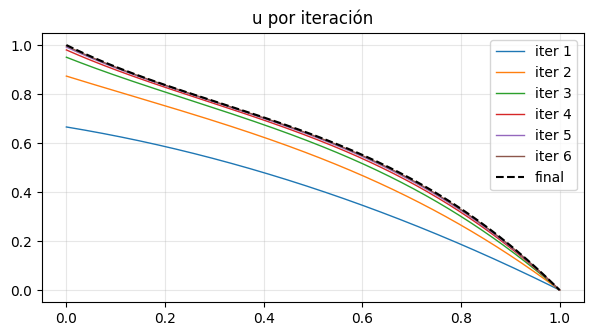

In [5]:
A, B, C, x0 = 1, 1, 4, 1.0
res = fbsm(lambda t, x, u: -0.5*x**2 + C*u,
           lambda t, x, u, l: -A + l*x,
           lambda t, x, l: C*l/(2*B),
           x0, lambda xT: np.zeros(1), 1.0, historia=True, tol=1e-6)
print('iteraciones:', res['iters'])
for i, uk in enumerate(res['hist'][:6]):
    plt.plot(res['t'], uk[:, 0], lw=1, label=f'iter {i+1}')
plt.plot(res['t'], res['u'][:, 0], 'k--', label='final'); plt.legend(); plt.title('u por iteración'); plt.show()

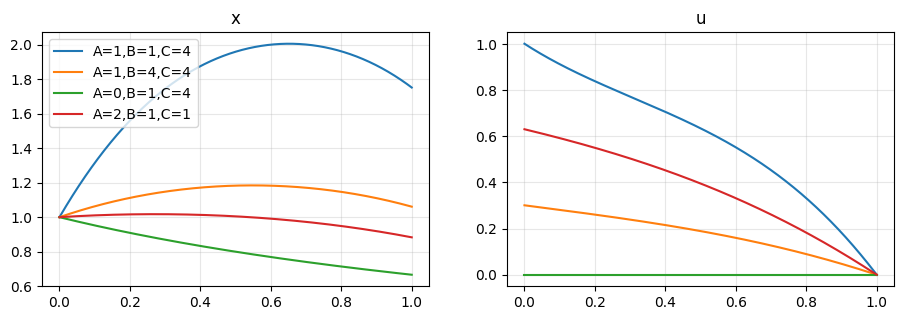

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for (A, B, C) in [(1, 1, 4), (1, 4, 4), (0, 1, 4), (2, 1, 1)]:
    r = fbsm(lambda t, x, u: -0.5*x**2 + C*u, lambda t, x, u, l: -A + l*x,
             lambda t, x, l: C*l/(2*B), 1.0, lambda xT: np.zeros(1), 1.0)
    ax[0].plot(r['t'], r['x'][:, 0], label=f'A={A},B={B},C={C}'); ax[1].plot(r['t'], r['u'][:, 0])
ax[0].legend(); ax[0].set_title('x'); ax[1].set_title('u'); plt.show()

## 3. La relajación importa
Problema LQ de la Clase 2 (solución exacta conocida). Probamos distintos $\omega$.

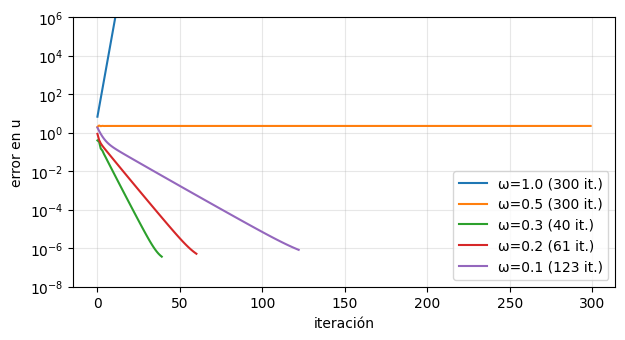

In [7]:
c = 3*np.exp(-4)/(3*np.exp(-4) + 1); d = 1/(3*np.exp(-4) + 1)
for omega in [1.0, 0.5, 0.3, 0.2, 0.1]:
    r = fbsm(lambda t, x, u: x + u, lambda t, x, u, l: 3*x - l, lambda t, x, l: l,
             1.0, lambda xT: np.zeros(1), 1.0, omega=omega, maxit=300, tol=1e-8, historia=True)
    ua = c*np.exp(2*r['t']) - 3*d*np.exp(-2*r['t'])
    errs = [np.abs(h[:, 0] - ua).max() for h in r['hist']]
    plt.semilogy(errs, label=f'ω={omega} ({r["iters"]} it.)')
plt.ylim(1e-8, 1e6); plt.xlabel('iteración'); plt.ylabel('error en u'); plt.legend(); plt.show()

## 4. Orden de convergencia en $N$

In [8]:
Ns = [25, 50, 100, 200, 400]; errs = []
for N in Ns:
    r = fbsm(lambda t, x, u: x + u, lambda t, x, u, l: 3*x - l, lambda t, x, l: l,
             1.0, lambda xT: np.zeros(1), 1.0, N=N, omega=0.3, tol=1e-12, maxit=500)
    ua = c*np.exp(2*r['t']) - 3*d*np.exp(-2*r['t'])
    errs.append(np.abs(r['u'][:, 0] - ua).max())
print('errores:', errs)
print('orden estimado:', np.polyfit(np.log(1/np.array(Ns)), np.log(errs), 1)[0])

errores: [np.float64(0.0004801753302021705), np.float64(0.00012000441841197862), np.float64(2.9998626417171437e-05), np.float64(7.499705338087637e-06), np.float64(1.8749305246146264e-06)]
orden estimado: 2.0001270474788955


## 5. Método de tiro
Para el Lab 1: incógnita $\lambda_0=\lambda(0)$, función de tiro $S(\lambda_0)=\lambda(1)$.

In [9]:
A, B, C = 1, 1, 4
def S(l0):
    s = solve_ivp(lambda t, y: [-0.5*y[0]**2 + C*C*y[1]/(2*B), -A + y[1]*y[0]], [0, 1], [1.0, l0],
                  rtol=1e-10, atol=1e-12)
    return s.y[1, -1]
l0 = brentq(S, 0.2, 0.8)
print('lambda(0) por tiro:', l0, '   lambda(0) por FBSM:', res['lam'][0, 0])
for l in [0.4, 0.5, 0.6, 0.8, 0.88]:
    print(f'S({l}) = {S(l):.4f}')

lambda(0) por tiro: 0.5008589766803931    lambda(0) por FBSM: 0.5008590555831685
S(0.4) = -0.5220
S(0.5) = -0.0074
S(0.6) = 1.5943
S(0.8) = 41.4215
S(0.88) = 633.0156


`solve_bvp` hace algo más robusto (colocación), equivalente a un tiro múltiple:

In [10]:
tb = np.linspace(0, 1, 30)
sb = solve_bvp(lambda t, y: np.vstack([-0.5*y[0]**2 + C*C*y[1]/(2*B), -A + y[1]*y[0]]),
               lambda ya, yb: np.array([ya[0] - 1, yb[1]]), tb, np.zeros((2, tb.size)))
print(sb.message, '  lambda(0) =', sb.sol(0)[1])

The algorithm converged to the desired accuracy.   lambda(0) = 0.5008575149224506


### Tiro con Newton: la derivada sale de la ecuación variacional (Ejercicio 6b)
Con $y=(x,\lambda)$ y $\dot y=F(t,y)$, la matriz $Y=\partial y/\partial\lambda_0$ cumple $\dot Y=D_yF\,Y$, $Y(0)=(0,1)$.
Integrando $y$ e $Y$ juntos se obtiene $S(\lambda_0)=\lambda(1)$ **y** $S'(\lambda_0)=Y_2(1)$ en una sola pasada.
Para el Lab 1: $D_yF=\begin{pmatrix}-x & C^2/(2B)\\ \lambda & x\end{pmatrix}$.

In [11]:
def S_y_dS(l0, A=1, B=1, C=4):
    def F(t, y):
        x, l, y1, y2 = y
        J = np.array([[-x, C*C/(2*B)], [l, x]])          # jacobiano del sistema (x, lambda)
        dY = J @ np.array([y1, y2])
        return [-0.5*x**2 + C*C*l/(2*B), -A + l*x, dY[0], dY[1]]
    s = solve_ivp(F, [0, 1], [1.0, l0, 0.0, 1.0], rtol=1e-11, atol=1e-12)
    return s.y[1, -1], s.y[3, -1]                        # S(l0) = lambda(1),  S'(l0) = Y_2(1)

def newton_tiro(l0, maxit=8):
    for k in range(maxit):
        S, dS = S_y_dS(l0)
        print(f'k={k}  lambda0={l0:.10f}  S={S: .3e}')
        if abs(S) < 1e-13 or not np.isfinite(S) or abs(S) > 1e10:
            break
        l0 = l0 - S/dS
    return l0

print('Semilla 0.45:'); newton_tiro(0.45)
print('\nSemilla 0.3:');  newton_tiro(0.3)
print('\nCon brentq en [0.2, 0.8]:', brentq(lambda l: S_y_dS(l)[0], 0.2, 0.8))

Semilla 0.45:
k=0  lambda0=0.4500000000  S=-3.362e-01
k=1  lambda0=0.5186170836  S= 1.702e-01
k=2  lambda0=0.5025123113  S= 1.446e-02
k=3  lambda0=0.5008741315  S= 1.313e-04
k=4  lambda0=0.5008589780  S= 1.110e-08
k=5  lambda0=0.5008589767  S= 2.711e-16

Semilla 0.3:
k=0  lambda0=0.3000000000  S=-6.674e-01


k=1  lambda0=1.5686279452  S= 2.762e+25

Con brentq en [0.2, 0.8]: 0.5008589766758528


**Para interpretar:** desde $0.45$ Newton converge cuadráticamente (el error se eleva al cuadrado en cada paso).
Desde $0.3$ el primer paso salta a $\lambda_0\approx1.57$, donde la solución explota: es la sensibilidad del tiro.
`brentq`, con un intervalo con cambio de signo, no tiene ese problema.

## 5b. Estado final fijo: tiro + FBSM (Ejercicio 7)
Si $x(T)=x^1$ está fijo, $\lambda(T)$ es desconocido. Lo tratamos como parámetro $\beta$:
**lazo interno** = FBSM con $\lambda(T)=\beta$ (sólo cambia `lamT`); **lazo externo** = secante sobre
$V(\beta)=x(T;\beta)-x^1$.

In [12]:
def tiro_fbsm(f, dlam, ucalc, x0, x1, T, beta0, beta1, tol=1e-9, maxit=30, **kw):
    """Secante sobre beta = lambda(T); en cada paso, un FBSM completo con lambda(T) = beta."""
    def V(beta):
        r = fbsm(f, dlam, ucalc, x0, lambda xT: np.array([beta]), T, tol=1e-8, **kw)
        return r['x'][-1, 0] - x1, r
    b0, b1 = beta0, beta1
    V0, _ = V(b0); V1, r = V(b1)
    hist = [(b0, V0), (b1, V1)]
    for j in range(maxit):
        if abs(V1) < tol:
            break
        b0, b1 = b1, b1 - V1*(b1 - b0)/(V1 - V0)
        V0 = V1; V1, r = V(b1); hist.append((b1, V1))
    return b1, r, hist

# (a) mínima energía: min ∫u^2, x' = a x + u, x(0)=1.5, x(2)=0  (como máximo: u = lambda/2)
a, T, x0 = 0.7, 2.0, 1.5
beta, r, hist = tiro_fbsm(lambda t, x, u: a*x + u, lambda t, x, u, l: -a*l, lambda t, x, l: l/2,
                         x0, 0.0, T, 0.0, -1.0)
for b, v in hist: print(f'beta = {b: .8f}   V(beta) = {v: .2e}')
print('exacto:', -4*a*x0/(1 - np.exp(-2*a*T))*np.exp(-a*T))

beta =  0.00000000   V(beta) =  6.08e+00
beta = -1.00000000   V(beta) =  5.67e-01
beta = -1.10276638   V(beta) = -1.13e-08
beta = -1.10276637   V(beta) =  1.32e-14
exacto: -1.1027665516197391


beta =  0.00000000   V(beta) = -2.47e-01
beta =  0.50000000   V(beta) =  5.76e-01
beta =  0.14999543   V(beta) =  2.79e-02
beta =  0.13216076   V(beta) = -3.20e-03
beta =  0.13399222   V(beta) =  1.75e-05
beta =  0.13398223   V(beta) =  1.10e-08
beta =  0.13398223   V(beta) = -3.60e-14


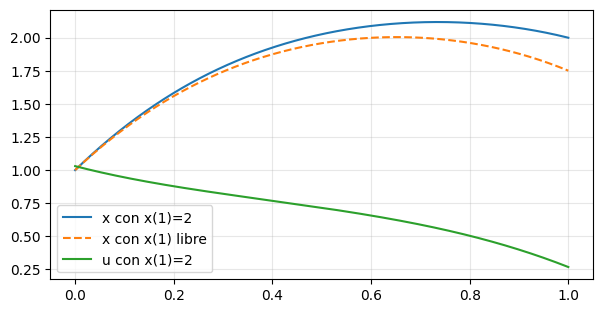

In [13]:
# (b) Lab 1 con x(1) = 2 fijo (no lineal)
A, B, C = 1, 1, 4
beta, r, hist = tiro_fbsm(lambda t, x, u: -0.5*x**2 + C*u, lambda t, x, u, l: -A + l*x,
                         lambda t, x, l: C*l/(2*B), 1.0, 2.0, 1.0, 0.0, 0.5)
for b, v in hist: print(f'beta = {b: .8f}   V(beta) = {v: .2e}')
libre = fbsm(lambda t, x, u: -0.5*x**2 + C*u, lambda t, x, u, l: -A + l*x,
             lambda t, x, l: C*l/(2*B), 1.0, lambda xT: np.zeros(1), 1.0)
plt.plot(r['t'], r['x'][:, 0], label='x con x(1)=2'); plt.plot(libre['t'], libre['x'][:, 0], '--', label='x con x(1) libre')
plt.plot(r['t'], r['u'][:, 0], label='u con x(1)=2'); plt.legend(); plt.show()

### Estado final fijo: $\beta^*$ en función del blanco $x^1$ (Ejercicio 7a)
Con $x(1)$ libre el óptimo llega a $x(1)\approx1.75$ con $\lambda(1)=0$. Si pedimos llegar a otro $x^1$, ¿cuánto vale
$\beta^*=\lambda(1)$?

x1 = 1.50:  beta* = -0.12334   (7 FBSM)


x1 = 1.75:  beta* = -0.00155   (6 FBSM)


x1 = 2.00:  beta* =  0.13398   (7 FBSM)


x1 = 2.50:  beta* =  0.44717   (6 FBSM)


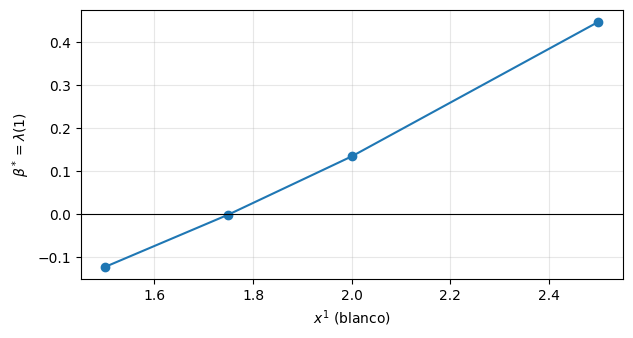

In [14]:
A, B, C = 1, 1, 4
f_lab = lambda t, x, u: -0.5*x**2 + C*u
dl_lab = lambda t, x, u, l: -A + l*x
uc_lab = lambda t, x, l: C*l/(2*B)
x1s = [1.5, 1.75, 2.0, 2.5]
betas = []
for x1 in x1s:
    b, r, hist = tiro_fbsm(f_lab, dl_lab, uc_lab, 1.0, x1, 1.0, 0.0, 0.5)
    betas.append(b)
    print(f'x1 = {x1:4.2f}:  beta* = {b: .5f}   ({len(hist)} FBSM)')
plt.plot(x1s, betas, 'o-'); plt.axhline(0, c='k', lw=0.8)
plt.xlabel('$x^1$ (blanco)'); plt.ylabel(r'$\beta^*=\lambda(1)$'); plt.show()

$\beta^*$ se anula cerca de $x^1\approx1.75$ (el $x(1)$ óptimo libre). Si se pide **más** que eso, $\beta^*>0$:
llegar más lejos tiene un precio sombra positivo; si se pide **menos**, $\beta^*<0$.

### Verificación con `solve_bvp`: $\beta$ como parámetro desconocido (Ejercicio 7b)
Incógnitas: $(x,\lambda)$ en la malla y el parámetro $p=\beta$. Condiciones de borde: $x(0)=1$, $x(1)=x^1$ y $\lambda(1)=p$
(tres ecuaciones para dos funciones y un parámetro).

In [15]:
x1 = 2.0
F7 = lambda t, y, p: np.vstack([-0.5*y[0]**2 + C*C*y[1]/(2*B), -A + y[1]*y[0]])
bc7 = lambda ya, yb, p: np.array([ya[0] - 1.0, yb[0] - x1, yb[1] - p[0]])
t7 = np.linspace(0, 1, 50)
sol7 = solve_bvp(F7, bc7, t7, np.vstack([np.linspace(1, x1, 50), np.full(50, 0.2)]), p=[0.1], tol=1e-8)
print(sol7.message, '  beta (solve_bvp) =', sol7.p[0], '  beta (tiro + FBSM) =', betas[x1s.index(2.0)])

The algorithm converged to the desired accuracy.   beta (solve_bvp) = 0.13398214006532702   beta (tiro + FBSM) = 0.1339822269424892


## 6. Método directo con adjunto discreto (= backprop)
Discretizamos con Euler y maximizamos $\mathcal J(u_0,\dots,u_{N-1})$ con L-BFGS-B. El gradiente se calcula con
$p_N=\phi'(x_N)$, $\partial\mathcal J/\partial u_k=h(L_u+p_{k+1}f_u)$, $p_k=p_{k+1}(1+hf_x)+hL_x$.

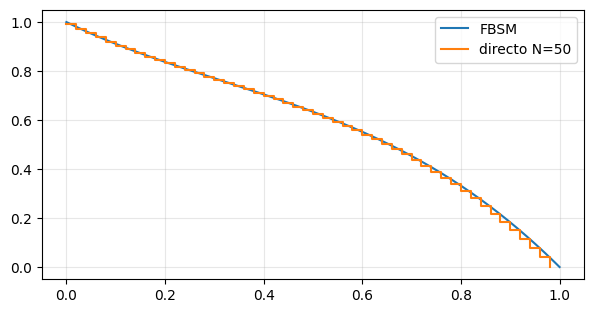

In [16]:
def directo(f, fx, fu, L, Lx, Lu, x0, T, N, cotas, phi=None, dphi=None, u0=None):
    h = T/N; t = np.linspace(0, T, N+1)
    def sim(u):
        x = np.zeros(N+1); x[0] = x0
        for k in range(N):
            x[k+1] = x[k] + h*f(t[k], x[k], u[k])
        return x
    def menosJ(u):
        x = sim(u)
        J = h*sum(L(t[k], x[k], u[k]) for k in range(N)) + (phi(x[N]) if phi else 0.0)
        p = dphi(x[N]) if dphi else 0.0; g = np.zeros(N)
        for k in range(N-1, -1, -1):
            g[k] = h*(Lu(t[k], x[k], u[k]) + p*fu(t[k], x[k], u[k]))
            p = p*(1 + h*fx(t[k], x[k], u[k])) + h*Lx(t[k], x[k], u[k])
        return -J, -g
    u0 = np.zeros(N) if u0 is None else u0
    r = minimize(menosJ, u0, jac=True, method='L-BFGS-B', bounds=[cotas]*N)
    return t, sim(r.x), r.x, -r.fun, menosJ

A, B, C = 1, 1, 4
t, x, u, J, menosJ = directo(lambda t, x, u: -0.5*x**2 + C*u, lambda t, x, u: -x, lambda t, x, u: C,
                             lambda t, x, u: A*x - B*u**2, lambda t, x, u: A, lambda t, x, u: -2*B*u,
                             1.0, 1.0, 50, (None, None))
plt.plot(res['t'], res['u'][:, 0], label='FBSM'); plt.step(t[:-1], u, where='post', label='directo N=50')
plt.legend(); plt.show()

Chequeo del gradiente discreto contra diferencias finitas:

In [17]:
u_test = np.random.default_rng(0).normal(size=50)
_, g = menosJ(u_test); e = np.zeros(50); e[17] = 1e-6
fd = (menosJ(u_test + e)[0] - menosJ(u_test - e)[0])/2e-6
print('adjunto discreto:', g[17], '  diferencias finitas:', fd)

adjunto discreto: -0.05609288672754288   diferencias finitas: -0.056092886668857034


## Para explorar
1. Bacterias con el método directo (incluye costo final: usar `phi` y `dphi`).
2. Tumor de la Clase 3 con el método directo para $N=20,40,80$: graficar $p_k$ y compararlo con $\lambda(t)=-e^{\alpha(T-t)}$.
3. ¿Qué método es más rápido para $N=1000$? Medir con `%timeit`.